In [86]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [87]:
df=pd.read_csv('Travel.csv')

In [88]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [89]:
df.shape

(4888, 20)

In [90]:
df.duplicated().sum()

np.int64(0)

In [91]:
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [92]:
df.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                         float64
TypeofContact                object
CityTier                      int64
DurationOfPitch             float64
Occupation                   object
Gender                       object
NumberOfPersonVisiting        int64
NumberOfFollowups           float64
ProductPitched               object
PreferredPropertyStar       float64
MaritalStatus                object
NumberOfTrips               float64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting    float64
Designation                  object
MonthlyIncome               float64
dtype: object

In [93]:
df['ProdTaken'].value_counts()

ProdTaken
0    3968
1     920
Name: count, dtype: int64

In [94]:
df['Gender'].value_counts()

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64

In [95]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64

In [96]:
df['Gender']=df['Gender'].replace('Fe Male','Female')

In [97]:
df['Gender'].value_counts()

Gender
Male      2916
Female    1972
Name: count, dtype: int64

In [98]:
df['MaritalStatus']=df['MaritalStatus'].replace('Unmarried','Single')

In [99]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married     2340
Single      1598
Divorced     950
Name: count, dtype: int64

In [100]:
# Removing all the null values

In [101]:
features_with_na=[feature for feature in df.columns if df[feature].isnull().sum()>=1]

In [102]:
features_with_na

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [103]:
df[features_with_na].columns

Index(['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome'],
      dtype='object')

In [104]:
col=['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome']
      

In [105]:
# Access only numerical column

In [106]:
df_numeric=df[features_with_na][col].select_dtypes('Float64','int64')

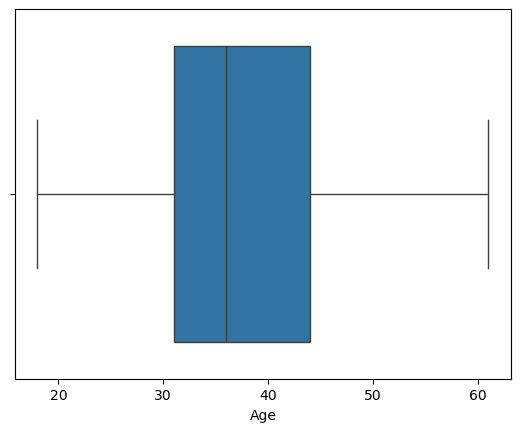

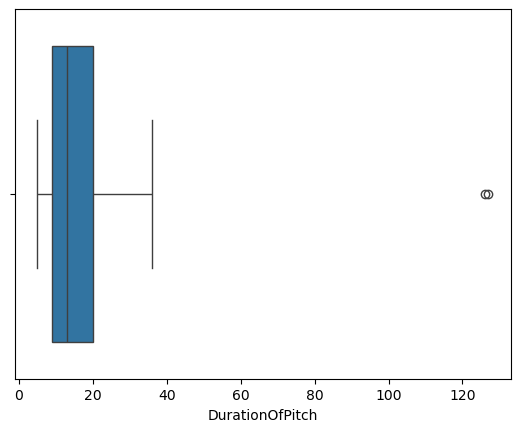

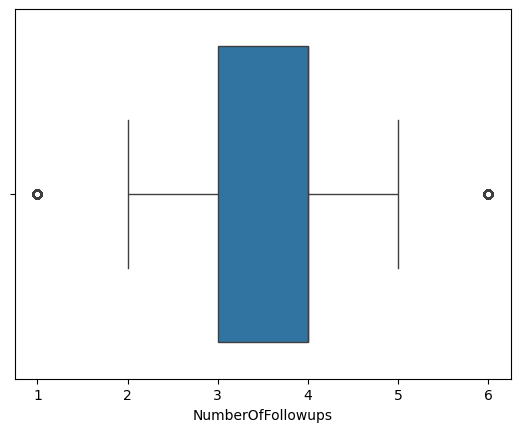

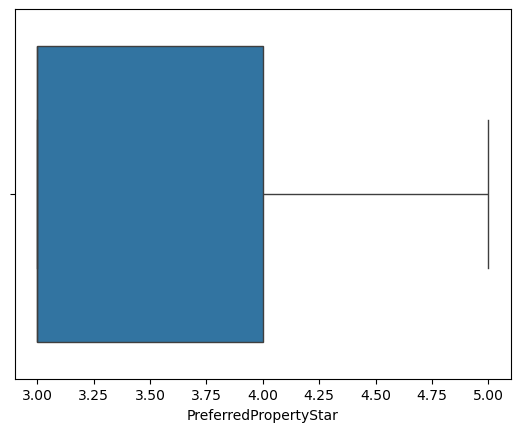

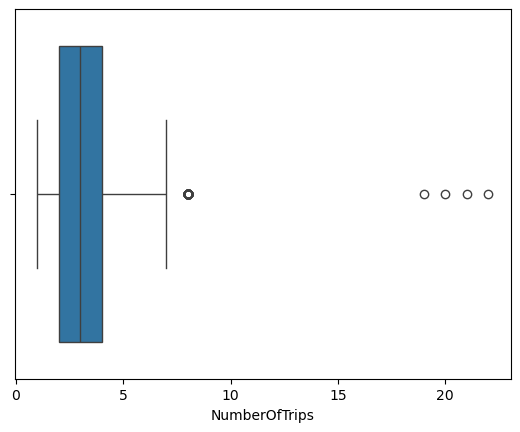

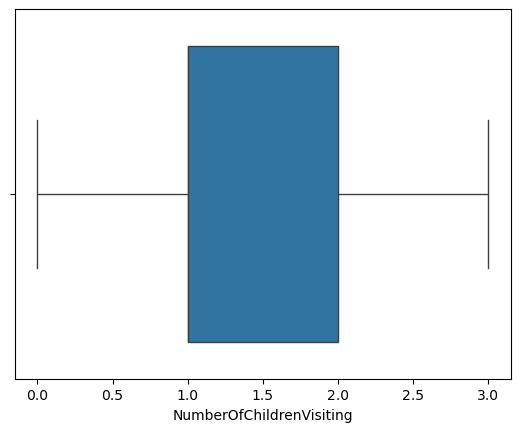

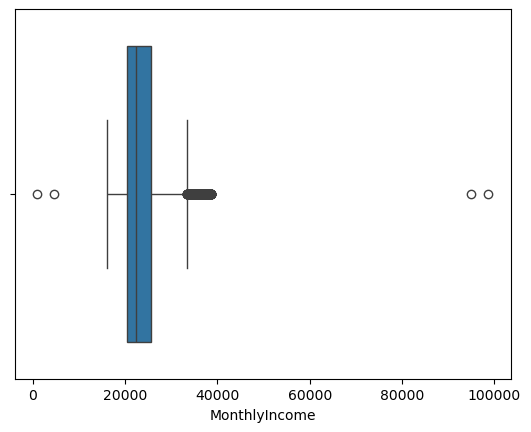

In [107]:
for col in df_numeric.columns:
    plt.figure()
    sns.boxplot(x=df_numeric[col])

In [108]:
df['Age']=df['Age'].fillna(df['Age'].mean())
df['DurationOfPitch']=df['DurationOfPitch'].fillna(df['DurationOfPitch'].median())
df['NumberOfFollowups']=df['NumberOfFollowups'].fillna(df['NumberOfFollowups'].median())
df['TypeofContact']=df['TypeofContact'].fillna(df['TypeofContact'].mode().iloc[0])
df['PreferredPropertyStar']=df['PreferredPropertyStar'].fillna(df['PreferredPropertyStar'].mean())
df['NumberOfTrips']=df['NumberOfTrips'].fillna(df['NumberOfTrips'].mean())
df['NumberOfChildrenVisiting']=df['NumberOfChildrenVisiting'].fillna(df['NumberOfChildrenVisiting'].median())
df['MonthlyIncome']=df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())

In [109]:
df.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [110]:
df.drop("CustomerID",axis=1,inplace=True)

In [111]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

# Feature Engineering

In [112]:
df['TotalVisiting']=df['NumberOfPersonVisiting']+df['NumberOfChildrenVisiting']

In [113]:
df.drop(columns=['NumberOfPersonVisiting','NumberOfChildrenVisiting'],inplace=True)

In [114]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfFollowups', 'ProductPitched',
       'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'Designation', 'MonthlyIncome',
       'TotalVisiting'],
      dtype='object')

In [115]:
# model Training

In [116]:
X=df.drop('ProdTaken',axis=1)
y=df['ProdTaken']

In [117]:
from sklearn.model_selection import train_test_split

In [118]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [119]:
# Column Transformer=Used to apply different preprocessing technique on different column

In [120]:
from sklearn.compose import ColumnTransformer

In [121]:
cat_feature=X.select_dtypes(include='object').columns
num_feature=X.select_dtypes(exclude='object').columns

In [122]:
cat_feature

Index(['TypeofContact', 'Occupation', 'Gender', 'ProductPitched',
       'MaritalStatus', 'Designation'],
      dtype='object')

In [123]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [124]:
# Create an object of both prepocessing

In [125]:
numeric_transformer=StandardScaler()
oh_transformer=OneHotEncoder()

In [126]:
preprocessing=ColumnTransformer(
    [
        ("OneHotEncoder",oh_transformer,cat_feature),
        ("StandardScaler",numeric_transformer,num_feature)

    ]
)

In [127]:
# Apply transformation on training data 

In [ ]:
X_train=preprocessing.fit_transform(X_train)


In [129]:
X_test=preprocessing.transform(X_test)

In [135]:
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [137]:
models={
    "Random Forest":RandomForestClassifier(),
    "Ada boost":AdaBoostClassifier(),
    "Gradient boost":GradientBoostingClassifier(),
    "Decision tree":DecisionTreeClassifier(),
    "Xgboost":XGBClassifier()

}

In [144]:
for i in range(len(list(models))):
    model=list(models.values())[i]

    # model training
    model.fit(X_train,y_train)

    # make prediction
    y_pred_train=model.predict(X_train)
    y_pred_test=model.predict(X_test)

    print(list(models.keys())[i])

    print("Training accurancy")
    print(f"Accurancy={accuracy_score(y_train,y_pred_train)}")    
    print(f"precision={precision_score(y_train,y_pred_train)}")
    print(f"recall={recall_score(y_train,y_pred_train)}")
    print(f"f1-score={f1_score(y_train,y_pred_train)}")

    print("Testing accurancy")
    print(f"Accurancy={accuracy_score(y_test,y_pred_test)}")
    print(f"precision={precision_score(y_test,y_pred_test)}")
    print(f"recall={recall_score(y_test,y_pred_test)}")
    print(f"f1-score={f1_score(y_test,y_pred_test)}")

    print("-------------------------------------------------------")

Random Forest
Training accurancy
Accurancy=1.0
precision=1.0
recall=1.0
f1-score=1.0
Testing accurancy
Accurancy=0.9274028629856851
precision=0.9761904761904762
recall=0.643979057591623
f1-score=0.7760252365930599
-------------------------------------------------------
Ada boost
Training accurancy
Accurancy=0.8506393861892583
precision=0.7935222672064778
recall=0.26886145404663925
f1-score=0.4016393442622951
Testing accurancy
Accurancy=0.8404907975460123
precision=0.7868852459016393
recall=0.2513089005235602
f1-score=0.38095238095238093
-------------------------------------------------------
Gradient boost
Training accurancy
Accurancy=0.8936061381074168
precision=0.8735083532219571
recall=0.5020576131687243
f1-score=0.6376306620209059
Testing accurancy
Accurancy=0.8588957055214724
precision=0.7731958762886598
recall=0.39267015706806285
f1-score=0.5208333333333334
-------------------------------------------------------
Decision tree
Training accurancy
Accurancy=1.0
precision=1.0
recall=

In [145]:
from sklearn.model_selection import RandomizedSearchCV 

In [146]:
xgb_data={
    "n_estimators":[100,200,500,700],
    "max_depth":[3,5,7,10],
    "learning_rate":[0.1,0.2,0.01,0.05]
}

In [150]:
xgb_model=XGBClassifier(
    objective="binary:logistic",
    evaluation_metric="f1_score",
    use_label_encoder=False
      
)

In [151]:
best_params=RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_data,
    cv=5,
    random_state=42
)

In [152]:
best_params.fit(X_train,y_train)

,estimator,"XGBClassifier...obs=None, ...)"
,param_distributions,"{'learning_rate': [0.1, 0.2, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...]}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [154]:
best_params.best_params_

{'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.05}

In [155]:
best_params.best_score_

np.float64(0.929156010230179)